In [1]:
import osmnx as ox

print("OSMnx version:", ox.__version__)
print("OSMnx is working!")

OSMnx version: 2.2.0
OSMnx is working!


In [2]:
import osmnx as ox

ox.settings.use_cache = True
ox.settings.log_console = True

G = ox.graph_from_place(
    "Hyderabad, Telangana, India",
    network_type="drive",
    simplify=True
)

print("Road network downloaded!")

Road network downloaded!


In [3]:
nodes, edges = ox.graph_to_gdfs(G)

print("Nodes:", len(nodes))
print("Road segments:", len(edges))

Nodes: 138471
Road segments: 359510


In [4]:
print(edges.head())

                                osmid   highway maxspeed  \
u         v           key                                  
245640546 11521379587 0     436397571     trunk       60   
          307055815   0    1240103685     trunk       60   
245640607 3169797989  0     311357324  tertiary      NaN   
          2236747949  0      22831055     trunk       60   
          2237001679  0     166515437  tertiary      NaN   

                                                name  oneway    ref reversed  \
u         v           key                                                      
245640546 11521379587 0    Hyderabad Janagam Highway    True  NH163    False   
          307055815   0    Hyderabad Janagam Highway    True  NH163    False   
245640607 3169797989  0                          NaN   False    NaN    False   
          2236747949  0                          NaN    True  NH163    False   
          2237001679  0                     Street 8   False    NaN     True   

                  

In [5]:
print(edges.columns.tolist())

['osmid', 'highway', 'maxspeed', 'name', 'oneway', 'ref', 'reversed', 'length', 'geometry', 'lanes', 'access', 'bridge', 'junction', 'tunnel', 'area', 'width', 'service']


In [6]:
print("Total road records:", len(edges))

print("Missing values:")
print(edges.isnull().sum())

print("Geometry types:")
print(edges.geom_type.value_counts())

print("CRS:")
print(edges.crs)

Total road records: 359510
Missing values:
osmid            0
highway          0
maxspeed    348815
name        319435
oneway           0
ref         356053
reversed         0
length           0
geometry         0
lanes       354303
access      356225
bridge      358693
junction    359179
tunnel      359413
area        359477
width       359442
service     359508
dtype: int64
Geometry types:
LineString    359510
Name: count, dtype: int64
CRS:
epsg:4326


In [7]:
total_length_km = edges["length"].sum() / 1000

print("Total road length:", round(total_length_km, 2), "KM")

Total road length: 20569.74 KM


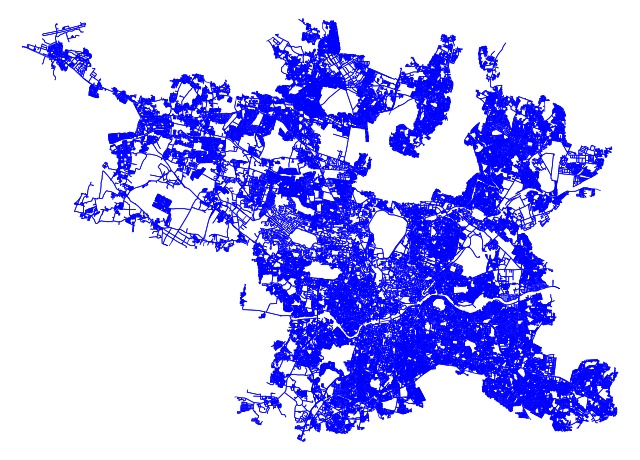

In [8]:
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_color="blue",
    edge_linewidth=0.5,
    bgcolor="white"
)

In [9]:
edges_projected = edges.to_crs(epsg=32644)

print(edges_projected.crs)

EPSG:32644


In [10]:
edges_clean = edges.copy()

print("Original records:", len(edges))
print("Working records:", len(edges_clean))

Original records: 359510
Working records: 359510


In [11]:
edges_clean["road_name"] = (
    edges_clean["name"].fillna("Unnamed road")
)

print(edges_clean[["name", "road_name"]].head(10))

                                                name  \
u         v           key                              
245640546 11521379587 0    Hyderabad Janagam Highway   
          307055815   0    Hyderabad Janagam Highway   
245640607 3169797989  0                          NaN   
          2236747949  0                          NaN   
          2237001679  0                     Street 8   
245640612 9867361507  0                          NaN   
          307055883   0                          NaN   
245640872 7676161810  0              Sainikpuri Road   
245640873 13371439861 0              Sainikpuri Road   
245640989 2763577069  0                          NaN   

                                           road_name  
u         v           key                             
245640546 11521379587 0    Hyderabad Janagam Highway  
          307055815   0    Hyderabad Janagam Highway  
245640607 3169797989  0                 Unnamed road  
          2236747949  0                 Unnamed road

In [12]:
road_types = edges_clean.explode("highway")["highway"].value_counts()

print(road_types)

highway
residential       318931
tertiary           21002
secondary           7412
living_street       4366
primary             3509
trunk               2049
unclassified        1486
primary_link         380
tertiary_link        322
trunk_link           307
secondary_link       261
motorway              38
motorway_link         23
Name: count, dtype: int64


In [13]:
edges_clean["road_type"] = edges_clean["highway"].apply(
    lambda x: ", ".join(x) if isinstance(x, list) else str(x)
)

print(edges_clean[["road_type", "road_name"]].head())

                          road_type                  road_name
u         v           key                                     
245640546 11521379587 0       trunk  Hyderabad Janagam Highway
          307055815   0       trunk  Hyderabad Janagam Highway
245640607 3169797989  0    tertiary               Unnamed road
          2236747949  0       trunk               Unnamed road
          2237001679  0    tertiary                   Street 8


In [14]:
edges_clean = edges_clean.to_crs(epsg=32644)

edges_clean["length_km"] = (
    edges_clean.geometry.length / 1000
)

print(edges_clean[["road_name", "road_type", "length_km"]].head())

                                           road_name road_type  length_km
u         v           key                                                
245640546 11521379587 0    Hyderabad Janagam Highway     trunk   0.007183
          307055815   0    Hyderabad Janagam Highway     trunk   0.020516
245640607 3169797989  0                 Unnamed road  tertiary   0.008012
          2236747949  0                 Unnamed road     trunk   0.214561
          2237001679  0                     Street 8  tertiary   0.052730


In [15]:
print("Total records:", len(edges_clean))

print("CRS:", edges_clean.crs)

print("Invalid geometries:",
      (~edges_clean.geometry.is_valid).sum())

print("Empty geometries:",
      edges_clean.geometry.is_empty.sum())

print("Missing road names:",
      edges_clean["road_name"].isnull().sum())

Total records: 359510
CRS: EPSG:32644
Invalid geometries: 0
Empty geometries: 0
Missing road names: 0


In [16]:
import os

output_folder = r"C:\THIRUMAL FILES\Geospatial_Data_Engineering\02_Hyderabad_Road_Analysis\output"

os.makedirs(output_folder, exist_ok=True)

output_path = os.path.join(
    output_folder,
    "hyderabad_roads_clean.gpkg"
)

edges_clean.to_file(
    output_path,
    layer="roads",
    driver="GPKG",
    index=True
)

print("Cleaned road dataset saved successfully!")

Cleaned road dataset saved successfully!


In [17]:
road_summary = (
    edges_clean
    .groupby("road_type")
    .agg(
        road_segments=("road_type", "count"),
        total_length_km=("length_km", "sum")
    )
    .reset_index()
    .sort_values("road_segments", ascending=False)
)

print(road_summary)

                     road_type  road_segments  total_length_km
7                  residential         318365     17585.655886
13                    tertiary          20991      1306.535970
9                    secondary           7409       564.507646
0                living_street           3856       171.734203
4                      primary           3507       376.178368
17                       trunk           2048       242.067189
20                unclassified           1432       152.123695
1   living_street, residential            510        46.148245
6                 primary_link            380        10.365071
15               tertiary_link            320         9.491155
19                  trunk_link            304        10.263946
12              secondary_link            261         7.793015
21   unclassified, residential             50        17.234195
2                     motorway             38        31.107660
3                motorway_link             23         8

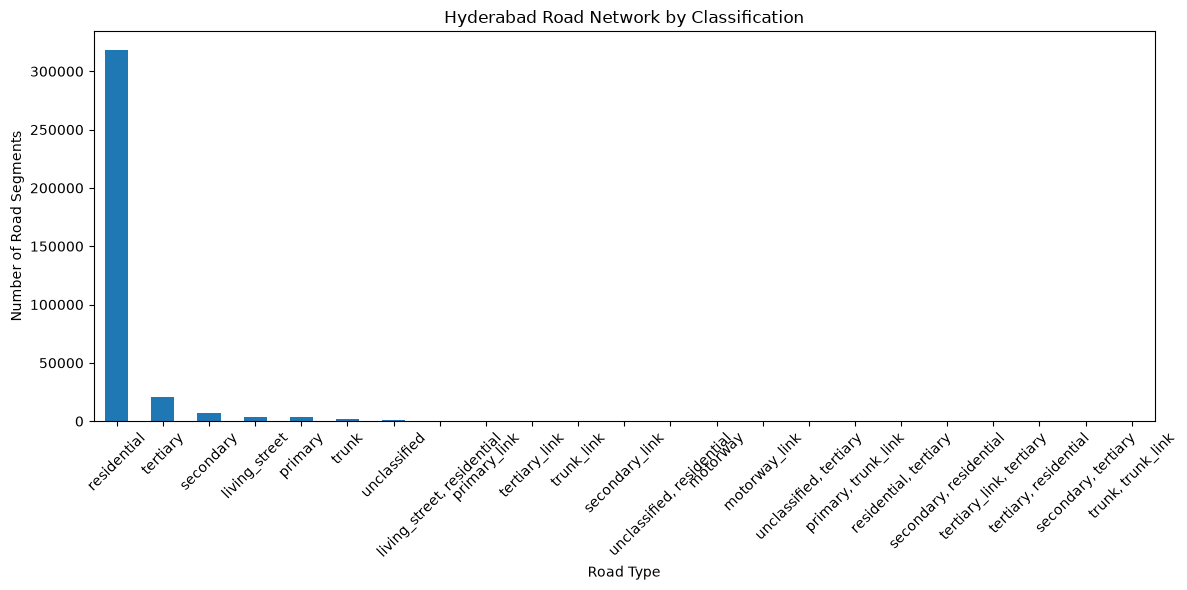

In [18]:
import matplotlib.pyplot as plt

road_summary.plot(
    x="road_type",
    y="road_segments",
    kind="bar",
    figsize=(12, 6),
    legend=False
)

plt.title("Hyderabad Road Network by Classification")
plt.xlabel("Road Type")
plt.ylabel("Number of Road Segments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
report_path = os.path.join(
    output_folder,
    "road_classification_summary.csv"
)

road_summary.to_csv(report_path, index=False)

print("Road classification report saved!")

Road classification report saved!


In [20]:
# Select only the important columns for the database
roads_for_db = edges_clean[
    ["road_name", "road_type", "length_km", "oneway", "geometry"]
].copy()

# Convert oneway values to text
roads_for_db["oneway"] = roads_for_db["oneway"].astype(str)

print("Records to upload:", len(roads_for_db))
print("CRS:", roads_for_db.crs)
print(roads_for_db.head())

Records to upload: 359510
CRS: EPSG:32644
                                           road_name road_type  length_km  \
u         v           key                                                   
245640546 11521379587 0    Hyderabad Janagam Highway     trunk   0.007183   
          307055815   0    Hyderabad Janagam Highway     trunk   0.020516   
245640607 3169797989  0                 Unnamed road  tertiary   0.008012   
          2236747949  0                 Unnamed road     trunk   0.214561   
          2237001679  0                     Street 8  tertiary   0.052730   

                          oneway  \
u         v           key          
245640546 11521379587 0     True   
          307055815   0     True   
245640607 3169797989  0    False   
          2236747949  0     True   
          2237001679  0    False   

                                                                    geometry  
u         v           key                                                     
2456405

In [21]:
roads_for_db.to_postgis(
    name="hyderabad_roads",
    con=engine,
    schema="public",
    if_exists="replace",
    index=False,
    chunksize=5000
)

print("Hyderabad road network uploaded successfully!")

NameError: name 'engine' is not defined

In [22]:
roads_for_db.to_postgis(
    name="hyderabad_roads",
    con=engine,
    schema="public",
    if_exists="replace",
    index=False,
    chunksize=5000
)

print("Hyderabad road network uploaded successfully!")

NameError: name 'engine' is not defined

In [23]:
from sqlalchemy import create_engine

username = "postgres"
password = "YOUR_POSTGRES_PASSWORD"
host = "localhost"
port = "5432"
database = "geospatial_db"

engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

print("PostgreSQL connection successful!")

PostgreSQL connection successful!


In [26]:
roads_for_db.to_postgis(
    name="hyderabad_roads",
    con=engine,
    schema="public",
    if_exists="replace",
    index=False,
    chunksize=5000
)

print("Hyderabad road network uploaded successfully!")

OperationalError: (psycopg2.OperationalError) connection to server at "localhost" (::1), port 5432 failed: FATAL:  password authentication failed for user "postgres"

(Background on this error at: https://sqlalche.me/e/21/e3q8)

In [25]:
password = "Austin3:16"

In [27]:
from sqlalchemy import create_engine

# PostgreSQL connection details
username = "postgres"
password = "Austin3:16"
host = "localhost"
port = "5432"
database = "geospatial_db"

# Create database connection
engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

# Upload Hyderabad road network
roads_for_db.to_postgis(
    name="hyderabad_roads",
    con=engine,
    schema="public",
    if_exists="replace",
    index=False,
    chunksize=5000
)

print("Hyderabad road network uploaded successfully!")

Hyderabad road network uploaded successfully!


In [1]:
import osmnx as ox
import geopandas as gpd

# Download Greater Hyderabad Municipal Corporation boundary
boundary = ox.geocode_to_gdf(
    "Greater Hyderabad Municipal Corporation, Telangana, India"
)

print("Boundary downloaded successfully")
print("CRS:", boundary.crs)
print("Geometry type:", boundary.geometry.geom_type.tolist())

boundary

Boundary downloaded successfully
CRS: epsg:4326
Geometry type: ['Polygon']


,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((78.47468 17.40755, 78.47482 17.40755...",78.474683,17.407313,78.476457,17.408493,248869047,way,236036933,17.407843,78.475535,amenity,townhall,30,0.000068,amenity,Greater Hyderabad Municipal Corporation,"Greater Hyderabad Municipal Corporation, NTR M..."


In [2]:
boundary_path = r"C:\THIRUMAL FILES\Geospatial_Data_Engineering\02_Hyderabad_Road_Analysis\output\hyderabad_boundary.gpkg"

boundary.to_file(
    boundary_path,
    layer="hyderabad_boundary",
    driver="GPKG"
)

print("Boundary saved successfully!")

Boundary saved successfully!


In [3]:
import os

boundary_path = r"C:\THIRUMAL FILES\Geospatial_Data_Engineering\02_Hyderabad_Road_Analysis\output\hyderabad_boundary.gpkg"

print("File exists:", os.path.exists(boundary_path))
print("File path:", boundary_path)

File exists: True
File path: C:\THIRUMAL FILES\Geospatial_Data_Engineering\02_Hyderabad_Road_Analysis\output\hyderabad_boundary.gpkg


In [4]:
print("Boundary name:")
print(boundary["display_name"].values)

print("\nBoundary area:")
print(boundary.to_crs(epsg=32644).geometry.area / 1_000_000)

print("\nBoundary bounds:")
print(boundary.total_bounds)

Boundary name:
<ArrowStringArray>
['Greater Hyderabad Municipal Corporation, NTR Marg, Gagan Mahal, Kavadiguda, Ward 78 Gunfoundry, Greater Hyderabad Municipal Corporation Central Zone, Hyderabad, Himayatnagar mandal, Hyderabad, Telangana, 500063, India']
Length: 1, dtype: str

Boundary area:
0    0.016144
dtype: float64

Boundary bounds:
[78.4746833 17.4073132 78.4764574 17.4084934]


In [5]:
print("Boundary CRS:", boundary.crs)
print("Major roads CRS:", edges_clean.crs)

print("\nMajor roads bounds:")
print(edges_clean.total_bounds)

Boundary CRS: epsg:4326


NameError: name 'edges_clean' is not defined

In [6]:
import geopandas as gpd

edges_clean = gpd.read_postgis(
    "SELECT * FROM public.hyderabad_roads",
    con=engine,
    geom_col="geometry"
)

print("Roads loaded:", len(edges_clean))
print("CRS:", edges_clean.crs)
print("Bounds:", edges_clean.total_bounds)

NameError: name 'engine' is not defined

In [7]:
from sqlalchemy import create_engine

username = "postgres"
password = "YOUR_ACTUAL_POSTGRES_PASSWORD"
host = "localhost"
port = "5432"
database = "geospatial_db"

engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

print("Database connection created!")

Database connection created!


In [8]:
with engine.connect() as connection:
    print(connection.exec_driver_sql(
        "SELECT version();"
    ).scalar())

OperationalError: (psycopg2.OperationalError) connection to server at "localhost" (::1), port 5432 failed: FATAL:  password authentication failed for user "postgres"

(Background on this error at: https://sqlalche.me/e/21/e3q8)

In [1]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from getpass import getpass

password = getpass("Enter PostgreSQL password: ")

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password="Austin3:16",
    host="localhost",
    port=5432,
    database="geospatial_db"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("PostgreSQL connection successful!")

PostgreSQL connection successful!
